<a href="https://colab.research.google.com/github/mferris03/TME_6015_Final/blob/main/TME6015_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install rlcard==1.2.0 remotezip scikit-learn pandas matplotlib

import json
import hashlib
import re
import random
import tomllib
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rlcard
from remotezip import RemoteZip
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from google.colab import drive

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

# Do not remount an already-mounted Drive.
if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive')
DATA_DIR = ROOT / 'acpc_2014_2pl_csv'  # ORIGINAL converted dataset; READ ONLY
MODEL_DIR = ROOT / 'poker_models'
FIGURE_DIR = MODEL_DIR / 'rank_cnn_figures'
for folder in (MODEL_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Original converted dataset not found: {DATA_DIR}')
CSV_FILES = sorted(DATA_DIR.glob('*.csv.gz'))
print('Converted CSV files found:', len(CSV_FILES))
if len(CSV_FILES) < 100:
    raise RuntimeError('Too few CSV files. Check the mounted Google Drive and DATA_DIR.')

ARCHIVE_URL = 'https://zenodo.org/records/17136841/files/poker-hand-histories.zip?download=1'
ZIP_HEADERS = {'Accept-Encoding':'identity'}
ARCHIVE_PREFIX = 'data/annual-computer-poker-competition/competitions/2014/logs/2pl_logs/2014_2pl/'
LOCAL_PHHS_DIR = Path('/content/acpc_phh')
SPLIT_PATH = MODEL_DIR / 'acpc_cnn129_original_selection_manifest.json'
MODEL_PATH = MODEL_DIR / 'poker_model_acpc_rank_cnn_position.keras'
LOG_PATH = MODEL_DIR / 'rank_cnn_position_training_log.csv'
ACTION_NAMES = ['Call','Raise','Fold','Check']

print('Reading converted CSVs from:', DATA_DIR)
print('Model checkpoint:', MODEL_PATH)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
Converted CSV files found: 6447
Reading converted CSVs from: /content/drive/MyDrive/acpc_2014_2pl_csv
Model checkpoint: /content/drive/MyDrive/poker_models/poker_model_acpc_rank_cnn_position.keras


In [2]:
PATTERN = re.compile(r'(?P<match>.+\.(?P<replicate>\d+))\.[01]\.phhs?\.csv(?:\.gz)?$')

# Reproduce the original notebook's exact filename enumeration and RNG sequence.
match_files = defaultdict(list)
match_replicate = {}
for path in sorted(DATA_DIR.iterdir()):
    if not path.is_file() or not path.name.endswith(('.csv', '.csv.gz')):
        continue
    m = PATTERN.fullmatch(path.name)
    if m:
        group = m.group('match')
        match_files[group].append(path)
        match_replicate[group] = int(m.group('replicate'))

if not match_files:
    raise RuntimeError('No converted ACPC match files matched the expected filename pattern.')

def reproduce_original_split():
    rng = np.random.default_rng(42)
    replicates = sorted(set(match_replicate.values()))
    rng.shuffle(replicates)
    n_holdout = max(1, round(len(replicates) * .15))
    replicate_splits = {
        'train': set(replicates[:-2 * n_holdout]),
        'val': set(replicates[-2 * n_holdout:-n_holdout]),
        'test': set(replicates[-n_holdout:]),
    }
    # This loop order and RNG advancement match original cell 8.
    sample_limits = {'train': 24, 'val': 6, 'test': 6}
    original = {}
    for split, replicate_ids in replicate_splits.items():
        eligible = [g for g in sorted(match_files)
                    if match_replicate[g] in replicate_ids]
        rng.shuffle(eligible)
        chosen = eligible[:sample_limits[split]]
        if len(chosen) != sample_limits[split]:
            raise RuntimeError(f'Only {len(chosen)} groups available for {split}')
        original[split] = [path for group in chosen for path in match_files[group]]

    # This duplicates the original expanded-training cell 15.
    original_train_files = set(original['train'])
    extra_candidates = [
        group for group, paths in sorted(match_files.items())
        if match_replicate[group] in replicate_splits['train']
        and original_train_files.isdisjoint(paths)
    ]
    extra_groups = np.random.default_rng(42).choice(
        extra_candidates, size=24, replace=False
    )
    extra_paths = [path for group in extra_groups for path in match_files[group]]
    return {
        'train': [p.name for p in original['train'] + extra_paths],
        'val': [p.name for p in original['val']],
        'test': [p.name for p in original['test']],
        'initial_train': [p.name for p in original['train']],
    }

if SPLIT_PATH.exists():
    saved = json.loads(SPLIT_PATH.read_text())
    split_names = {k: saved[k] for k in ('train', 'val', 'test', 'initial_train')}
    print('Restored manifest:', SPLIT_PATH)
else:
    split_names = reproduce_original_split()
    SPLIT_PATH.write_text(json.dumps(split_names, indent=2))
    print('Recreated original selection and saved manifest:', SPLIT_PATH)

for split in ('train', 'val', 'test'):
    missing = [name for name in split_names[split] if not (DATA_DIR/name).is_file()]
    if missing:
        raise FileNotFoundError(f'{len(missing)} missing CSVs in {split}: {missing[:3]}')
    print(f'{split:5}: {len(split_names[split]):3} converted CSV files')

for a,b in [('train','val'),('train','test'),('val','test')]:
    assert set(split_names[a]).isdisjoint(split_names[b])

# Fixed digest associates saved arrays with exactly these file lists.
MANIFEST_HASH = hashlib.sha256(
    json.dumps({k: split_names[k] for k in ('train','val','test')},
               sort_keys=True).encode()
).hexdigest()
print('Split fingerprint:', MANIFEST_HASH[:16])

Recreated original selection and saved manifest: /content/drive/MyDrive/poker_models/acpc_cnn129_original_selection_manifest.json
train:  96 converted CSV files
val  :  12 converted CSV files
test :  12 converted CSV files
Split fingerprint: dea4f01659b3c6bc


In [3]:
# RLCard's exact card ordering used by the original project.
encoder_env = rlcard.make('limit-holdem', config={'seed': SEED})
example_state, _ = encoder_env.reset()
card_index = {}
for suit in 'SHDC':
    for rank in '23456789TJQKA':
        card = suit + rank
        raw = dict(example_state['raw_obs'], hand=[card], public_cards=[])
        bits = encoder_env._extract_state(raw)['obs'][:52]
        positions = np.flatnonzero(bits)
        if len(positions) != 1:
            raise RuntimeError(f'Unexpected RLCard encoding: {card}, {positions}')
        card_index[card] = int(positions[0])
assert len(set(card_index.values())) == 52

OBS_COLS = [f'obs_{i}' for i in range(72)]
LEGAL_COLS = [f'legal_{i}' for i in range(4)]
READ_COLS = ['hand_id','source_file','player','street','action'] + OBS_COLS + LEGAL_COLS
DEAL_PATTERN = re.compile(r'([2-9TJQKA])([cdhs])')

def get_dealt_cards_for_file(source_file, archive):
    """Return (hand_number, player) -> two RLCard card indices."""
    local = LOCAL_PHHS_DIR / source_file
    if local.is_file():
        with local.open('rb') as f:
            content = tomllib.load(f)
    else:
        if archive is None:
            raise RuntimeError('A selected original PHH file is missing and no archive is open')
        with archive.open(source_file) as f:
            content = tomllib.load(f)
    hands = {'1':content} if source_file.lower().endswith('.phh') else content
    dealt = {}
    for number, hand in hands.items():
        hole = defaultdict(list)
        for action in hand.get('actions', []):
            parts = action.partition('#')[0].split()
            if len(parts) >= 4 and parts[:2] == ['d','dh']:
                card_pairs = DEAL_PATTERN.findall(parts[3])
                for rank, suit in card_pairs:
                    hole[parts[2]].append(card_index[suit.upper()+rank])
        for player, cards in hole.items():
            if len(cards) == 2:
                dealt[(str(number), player)] = cards
    return dealt

def build_129_for_split(split, archive=None):
    cache = MODEL_DIR / f'acpc_cnn129_{split}.npz'
    if cache.exists():
        with np.load(cache) as saved:
            stored_hash = str(saved['manifest_hash'].item()) if 'manifest_hash' in saved else ''
            if stored_hash == MANIFEST_HASH:
                X, y = saved['X'], saved['y']
                if X.ndim == 2 and X.shape[1] == 129 and len(X) == len(y):
                    print(f'{split}: loaded matching cached arrays {X.shape}')
                    return X, y
        print(f'{split}: old cache had a different split; rebuilding it')

    X_parts, y_parts = [], []
    for i, filename in enumerate(split_names[split], start=1):
        path = DATA_DIR / filename
        frame = pd.read_csv(path, usecols=READ_COLS)
        if frame.empty:
            continue
        source_files = frame['source_file'].unique()
        if len(source_files) != 1:
            raise RuntimeError(f'Unexpected multiple PHH sources in {filename}')
        source_file = str(source_files[0])
        dealt = get_dealt_cards_for_file(source_file, archive)

        hand_numbers = frame['hand_id'].astype(str).str.rsplit(':', n=1).str[-1]
        try:
            hole_indices = np.asarray(
                [dealt[(hand_no,player)] for hand_no,player in
                 zip(hand_numbers, frame['player'])], dtype=np.intp
            )
        except KeyError as exc:
            raise RuntimeError(f'PHH hole cards not found in {source_file}: {exc}') from exc

        obs = frame[OBS_COLS].to_numpy(dtype=np.uint8)
        legal = frame[LEGAL_COLS].to_numpy(dtype=np.uint8)
        labels = frame['action'].to_numpy(dtype=np.int32)
        if not np.isin(labels, [0,1,2,3]).all():
            raise RuntimeError(f'Unexpected action labels in {filename}')
        if not np.isin(obs, [0,1]).all() or not np.isin(legal, [0,1]).all():
            raise RuntimeError(f'Non-binary inputs in {filename}')
        if not legal[np.arange(len(labels)), labels].all():
            raise RuntimeError(f'Illegal logged action in {filename}')

        hole = np.zeros((len(frame),52), dtype=np.uint8)
        hole[np.arange(len(frame))[:,None], hole_indices] = 1
        visible = obs[:,:52]
        if np.any(hole > visible):
            raise RuntimeError(f'Card encoding mismatch in {filename}')
        board = visible - hole
        if not np.isin(board.sum(axis=1),[0,3,4,5]).all():
            raise RuntimeError(f'Invalid board card count in {filename}')

        first_player = frame.groupby(
            ['hand_id','street'], sort=False
        )['player'].transform('first')
        position = frame['player'].eq(first_player).to_numpy(dtype=np.uint8)[:,None]
        X = np.concatenate([hole, board, obs[:,52:72], position, legal], axis=1)
        assert X.shape[1] == 129
        X_parts.append(X)
        y_parts.append(labels)
        if i==1 or i%10==0 or i==len(split_names[split]):
            print(f'{split}: read {i}/{len(split_names[split])} existing CSVs / PHH deals',flush=True)

    if not X_parts:
        raise RuntimeError(f'No decision rows for split {split}')
    X = np.concatenate(X_parts)
    y = np.concatenate(y_parts)
    np.savez_compressed(cache, X=X, y=y, manifest_hash=MANIFEST_HASH)
    print(f'{split}: saved {X.shape} to {cache.name}')
    return X, y

# Only contact the remote archive when at least one cache must be constructed
# and at least one selected PHH is unavailable locally.
need_build = []
for split in ('train','val','test'):
    cache = MODEL_DIR / f'acpc_cnn129_{split}.npz'
    valid = False
    if cache.is_file():
        try:
            with np.load(cache) as saved:
                valid = ('manifest_hash' in saved and
                         str(saved['manifest_hash'].item()) == MANIFEST_HASH and
                         saved['X'].shape[1] == 129)
        except Exception:
            valid = False
    if not valid:
        need_build.append(split)

need_remote = False
for split in need_build:
    for filename in split_names[split]:
        # Read only one CSV row to discover its original PHH filename.
        first_row = pd.read_csv(DATA_DIR/filename, nrows=1, usecols=['source_file'])
        if len(first_row) and not (LOCAL_PHHS_DIR/str(first_row['source_file'].iloc[0])).is_file():
            need_remote = True
            break
    if need_remote:
        break

if need_remote:
    print('Reading ONLY selected PHH deal records from the remote ZIP; no CSV conversion.')
    with RemoteZip(ARCHIVE_URL, headers=ZIP_HEADERS, timeout=120) as archive:
        X_train_129,y_train = build_129_for_split('train',archive)
        X_val_129,y_val = build_129_for_split('val',archive)
        X_test_129,y_test = build_129_for_split('test',archive)
else:
    X_train_129,y_train = build_129_for_split('train')
    X_val_129,y_val = build_129_for_split('val')
    X_test_129,y_test = build_129_for_split('test')

for name,X,y in [('Training',X_train_129,y_train),('Validation',X_val_129,y_val),('Test',X_test_129,y_test)]:
    print(f'{name:10}: {len(y):,} decisions; X={X.shape}; actions={np.bincount(y,minlength=4)}')
if len(y_val) != 269292:
    print('WARNING: Validation count differs from your previous recorded 269,292 decisions.')
    print('Review the split manifest and original filenames before comparing historic metrics.')
else:
    print('Validation count matches the previous recorded 269,292 decisions.')

Reading ONLY selected PHH deal records from the remote ZIP; no CSV conversion.
train: read 1/96 existing CSVs / PHH deals
train: read 10/96 existing CSVs / PHH deals
train: read 20/96 existing CSVs / PHH deals
train: read 30/96 existing CSVs / PHH deals
train: read 40/96 existing CSVs / PHH deals
train: read 50/96 existing CSVs / PHH deals
train: read 60/96 existing CSVs / PHH deals
train: read 70/96 existing CSVs / PHH deals
train: read 80/96 existing CSVs / PHH deals
train: read 90/96 existing CSVs / PHH deals
train: read 96/96 existing CSVs / PHH deals
train: saved (2125782, 129) to acpc_cnn129_train.npz
val: read 1/12 existing CSVs / PHH deals
val: read 10/12 existing CSVs / PHH deals
val: read 12/12 existing CSVs / PHH deals
val: saved (269292, 129) to acpc_cnn129_val.npz
test: read 1/12 existing CSVs / PHH deals
test: read 10/12 existing CSVs / PHH deals
test: read 12/12 existing CSVs / PHH deals
test: saved (267766, 129) to acpc_cnn129_test.npz
Training  : 2,125,782 decisions; X

In [4]:
layers = keras.layers
keras.utils.set_random_seed(42)

# X format: 52 hole + 52 board + 20 betting + 1 position + 4 legal actions.
# Arrange the first 104 values into 13 ranks × 8 channels:
# four hole-card suits and four board-card suits per rank.
rank_columns = [
    offset + card_index[suit + rank]
    for rank in "23456789TJQKA"
    for offset in (0, 52)
    for suit in "SHDC"
]

inputs = keras.Input(shape=(129,), name="poker_state")

# Card branch. Flattening preserves the location of each response by rank.
cards = keras.ops.take(inputs, rank_columns, axis=1)
cards = layers.Reshape((13, 8))(cards)

# Separate the four hole-card suits from the four board-card suits.
hole_cards = cards[:, :, :4]   # Shape: (batch, 13 ranks, 4 suits)
board_cards = cards[:, :, 4:]  # Shape: (batch, 13 ranks, 4 suits)

# Count each rank in the player's hand and on the board.
hole_rank_counts = keras.ops.sum(hole_cards, axis=2)
board_rank_counts = keras.ops.sum(board_cards, axis=2)

# This is positive when a rank appears in both the hand and the board.
matched_ranks = hole_rank_counts * board_rank_counts

# Count each suit in the hand, on the board, and across both.
hole_suit_counts = keras.ops.sum(hole_cards, axis=1)
board_suit_counts = keras.ops.sum(board_cards, axis=1)
total_suit_counts = hole_suit_counts + board_suit_counts

relations = layers.Concatenate(name="card_relations")([
    hole_rank_counts,
    board_rank_counts,
    matched_ranks,
    hole_suit_counts,
    board_suit_counts,
    total_suit_counts,
])

ops = keras.ops

all_cards = hole_cards + board_cards
rank_counts = hole_rank_counts + board_rank_counts

# Made-hand indicators
paired_ranks = ops.sum(ops.cast(rank_counts >= 2, "int32"), axis=1)
has_pair = paired_ranks >= 1
has_two_pair = paired_ranks >= 2
has_trips = ops.any(rank_counts >= 3, axis=1)
has_quads = ops.any(ops.equal(rank_counts, 4), axis=1)
has_full_house = ops.logical_and(has_trips, paired_ranks >= 2)
has_flush = ops.any(total_suit_counts >= 5, axis=1)

# Rank order is 2, 3, ..., K, A. Include the ace-low straight.
straight_windows = [[12, 0, 1, 2, 3]] + [
    list(range(start, start + 5)) for start in range(9)
]
window_indices = [rank for window in straight_windows for rank in window]

rank_present = ops.cast(rank_counts > 0, "int32")
rank_windows = ops.reshape(
    ops.take(rank_present, window_indices, axis=1), (-1, 10, 5)
)
ranks_per_window = ops.sum(rank_windows, axis=2)
has_straight = ops.any(ops.equal(ranks_per_window, 5), axis=1)

suited_windows = ops.reshape(
    ops.take(all_cards, window_indices, axis=1), (-1, 10, 5, 4)
)
suited_ranks_per_window = ops.sum(suited_windows, axis=2)
has_straight_flush = ops.any(
    ops.any(ops.equal(suited_ranks_per_window, 5), axis=2),
    axis=1,
)

# A hole card matches the highest unpaired board rank.
rank_ids = ops.arange(13, dtype="int32")
top_board_rank = ops.max(
    ops.where(board_rank_counts > 0, rank_ids, -1),
    axis=1,
    keepdims=True,
)
pairs_board_rank = ops.logical_and(
    ops.equal(hole_rank_counts, 1),
    ops.equal(board_rank_counts, 1),
)
has_top_pair = ops.any(
    ops.logical_and(pairs_board_rank, ops.equal(rank_ids, top_board_rank)),
    axis=1,
)

# Draw indicators apply on the flop and turn.
board_size = ops.sum(board_rank_counts, axis=1)
can_draw = ops.logical_or(ops.equal(board_size, 3), ops.equal(board_size, 4))

flush_draw = ops.logical_and(
    can_draw,
    ops.logical_and(
        ops.logical_not(has_flush),
        ops.any(ops.equal(total_suit_counts, 4), axis=1),
    ),
)
straight_draw = ops.logical_and(
    can_draw,
    ops.logical_and(
        ops.logical_not(has_straight),
        ops.any(ops.equal(ranks_per_window, 4), axis=1),
    ),
)

hand_features = ops.cast(ops.stack([
    has_pair,
    has_two_pair,
    has_trips,
    has_straight,
    has_flush,
    has_full_house,
    has_quads,
    has_straight_flush,
    has_top_pair,
    flush_draw,
    straight_draw,
], axis=1), "float32")

print("Hand feature shape:", hand_features.shape)

cards = layers.Conv1D(32, kernel_size=3, padding="same", activation="relu")(cards)
cards = layers.Flatten()(cards)

# Betting branch: 20 betting + 1 position + 4 legal-mask features.
betting = keras.ops.take(inputs, list(range(104, 129)), axis=1)
betting = layers.Dense(32, activation="relu")(betting)

raw_cards = keras.ops.take(inputs, list(range(104)), axis=1)
combined = layers.Concatenate()([cards, betting, raw_cards])
combined = layers.Concatenate(name="merge_card_relations")([
    combined, relations
])
combined = layers.Concatenate(name="merge_made_hand_and_draws")([
    combined,
    hand_features,
])
combined = layers.Dense(64, activation="relu")(combined)
outputs = layers.Dense(4, activation="softmax")(combined)

poker_cnn = keras.Model(inputs, outputs, name="poker_rank_cnn")
poker_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)



poker_cnn.summary()
callbacks=[
    keras.callbacks.ModelCheckpoint(str(MODEL_PATH), monitor='val_loss',
                                    save_best_only=True,verbose=1),
    keras.callbacks.CSVLogger(str(LOG_PATH)),
    keras.callbacks.EarlyStopping(monitor='val_loss',patience=7,
                                  restore_best_weights=True),
]
history_cnn=poker_cnn.fit(
    X_train_129,y_train,
    validation_data=(X_val_129,y_val),
    batch_size=1024,epochs=20,callbacks=callbacks,verbose=2,
)
(MODEL_DIR/'rank_cnn_position_history.json').write_text(
    json.dumps({k:[float(x) for x in values]
                for k,values in history_cnn.history.items()},indent=2)
)
print('Best checkpoint saved at:',MODEL_PATH)

Hand feature shape: (None, 11)


Model: "poker_rank_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ poker_state         │ (None, 129)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ take (Take)         │ (None, 104)       │          0 │ poker_state[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 13, 8)     │          0 │ take[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 13, 4)     │          0 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 13, 4)     │          0 │ reshape[0][0]     │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sum (Sum)           │ (None, 13)        │          0 │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sum_1 (Sum)         │ (None, 13)        │          0 │ get_item_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 13)        │          0 │ sum[0][0],        │
│                     │                   │            │ sum_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ greater (Greater)   │ (None, 13)        │          0 │ add_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cast_1 (Cast)       │ (None, 13)        │          0 │ greater[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ take_1 (Take)       │ (None, 50)        │          0 │ cast_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sum_2 (Sum)         │ (None, 4)         │          0 │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sum_3 (Sum)         │ (None, 4)         │          0 │ get_item_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 10, 5)     │          0 │ take_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 13, 4)     │          0 │ get_item[0][0],   │
│                     │                   │            │ get_item_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 4)         │          0 │ sum_2[0][0],      │
│                     │                   │            │ sum_3[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sum_5 (Sum)         │ (None, 10)        │          0 │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ take_2 (Take)       │ (None, 50, 4)     │          0 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ greater_1 (Greater) │ (None, 13)        │          0 │ sum_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ greater_equal       │ (None, 13)        │          0 │ add_2[0][0]       │
│ (GreaterEqual)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ equal_1 (Equal)     │ (None, 10)        │          0 │ sum_5[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ greater_equal_5     │ (None, 4)         │          0 │ add[0][0]       

 Total params: 41,252 (161.14 KB)

 Trainable params: 41,252 (161.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20

Epoch 1: val_loss improved from None to 0.57683, saving model to /content/drive/MyDrive/poker_models/poker_model_acpc_rank_cnn_position.keras

Epoch 1: finished saving model to /content/drive/MyDrive/poker_models/poker_model_acpc_rank_cnn_position.keras
2076/2076 - 71s - 34ms/step - accuracy: 0.7014 - loss: 0.6266 - val_accuracy: 0.7326 - val_loss: 0.5768
Epoch 2/20

Epoch 2: val_loss improved from 0.57683 to 0.56021, saving model to /content/drive/MyDrive/poker_models/poker_model_acpc_rank_cnn_position.keras

Epoch 2: finished saving model to /content/drive/MyDrive/poker_models/poker_model_acpc_rank_cnn_position.keras
2076/2076 - 72s - 35ms/step - accuracy: 0.7268 - loss: 0.5812 - val_accuracy: 0.7428 - val_loss: 0.5602
Epoch 3/20

Epoch 3: val_loss improved from 0.56021 to 0.55336, saving model to /content/drive/MyDrive/poker_models/poker_model_acpc_rank_cnn_position.keras

Epoch 3: finished saving model to /content/drive/MyDrive/poker_models/poker_model_acpc_rank_cnn_pos

In [5]:
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f'CNN checkpoint missing: {MODEL_PATH}')
cnn=keras.models.load_model(MODEL_PATH,compile=False)
assert cnn.input_shape[-1]==129

def predict_legal(model,X):
    scores=model.predict(X,batch_size=2048,verbose=0)
    legal=X[:,-4:].astype(bool)
    return np.where(legal,scores,-np.inf).argmax(axis=1)

def evaluate_split(name,X,y):
    predicted=predict_legal(cnn,X)
    accuracy=float(np.mean(predicted==y))
    report=classification_report(y,predicted,labels=[0,1,2,3],
                                 target_names=ACTION_NAMES,zero_division=0,
                                 output_dict=True)
    matrix=confusion_matrix(y,predicted,labels=[0,1,2,3])
    pd.DataFrame(report).T.to_csv(FIGURE_DIR/f'{name}_classification_report.csv')
    pd.DataFrame(matrix,index=ACTION_NAMES,columns=ACTION_NAMES).to_csv(FIGURE_DIR/f'{name}_confusion_counts.csv')
    print(f'{name}: accuracy={accuracy:.2%}, macro F1={report["macro avg"]["f1-score"]:.3f}')
    print(classification_report(y,predicted,labels=[0,1,2,3],target_names=ACTION_NAMES,zero_division=0))
    return predicted,report

val_pred,val_report=evaluate_split('validation',X_val_129,y_val)
test_pred,test_report=evaluate_split('test',X_test_129,y_test)

validation: accuracy=75.57%, macro F1=0.745
              precision    recall  f1-score   support

        Call       0.76      0.81      0.78     75534
       Raise       0.78      0.73      0.75    115708
        Fold       0.70      0.70      0.70     21612
       Check       0.73      0.77      0.75     56438

    accuracy                           0.76    269292
   macro avg       0.74      0.75      0.75    269292
weighted avg       0.76      0.76      0.76    269292

test: accuracy=74.71%, macro F1=0.739
              precision    recall  f1-score   support

        Call       0.80      0.76      0.78     78848
       Raise       0.74      0.73      0.74    108936
        Fold       0.69      0.70      0.70     21509
       Check       0.71      0.77      0.74     58473

    accuracy                           0.75    267766
   macro avg       0.74      0.74      0.74    267766
weighted avg       0.75      0.75      0.75    267766



In [8]:

# ==========================================================
# LEGAL-MASKED ACCURACY AND FULL CLASSIFICATION METRICS
# Validation and held-out test
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

evaluation_results = {}
action_labels = np.arange(4)

for split_name, X, y in [
    ("validation", X_val_129, y_val),
    ("test", X_test_129, y_test),
]:
    # Use the saved best checkpoint loaded as 'cnn'
    probabilities = cnn.predict(
        X, batch_size=2048, verbose=0
    )

    legal = X[:, -4:].astype(bool)

    # Compare raw softmax predictions with legal-masked choices
    unmasked_pred = probabilities.argmax(axis=1)
    masked_pred = np.where(
        legal, probabilities, -np.inf
    ).argmax(axis=1)

    masked_accuracy = accuracy_score(y, masked_pred)
    unmasked_accuracy = accuracy_score(y, unmasked_pred)

    p, r, f1, support = precision_recall_fscore_support(
        y,
        masked_pred,
        labels=action_labels,
        zero_division=0
    )

    macro_p, macro_r, macro_f1, _ = (
        precision_recall_fscore_support(
            y, masked_pred,
            labels=action_labels,
            average="macro",
            zero_division=0
        )
    )

    weighted_p, weighted_r, weighted_f1, _ = (
        precision_recall_fscore_support(
            y, masked_pred,
            labels=action_labels,
            average="weighted",
            zero_division=0
        )
    )

    class_df = pd.DataFrame({
        "Action": ACTION_NAMES,
        "Precision": p,
        "Recall": r,
        "F1": f1,
        "Support": support
    })

    evaluation_results[split_name] = {
        "masked_accuracy": float(masked_accuracy),
        "unmasked_accuracy": float(unmasked_accuracy),
        "macro_precision": float(macro_p),
        "macro_recall": float(macro_r),
        "macro_f1": float(macro_f1),
        "weighted_precision": float(weighted_p),
        "weighted_recall": float(weighted_r),
        "weighted_f1": float(weighted_f1),
        "decisions": len(y),
        "classes": class_df
    }

    class_df.to_csv(
        FIGURE_DIR / f"{split_name}_precision_recall_f1.csv",
        index=False
    )

    print(f"\n{'='*55}")
    print(split_name.upper())
    print(f"{'='*55}")
    print(f"Decisions: {len(y):,}")
    print(f"Unmasked accuracy: {unmasked_accuracy:.2%}")
    print(f"Legal-masked accuracy: {masked_accuracy:.2%}")
    print(f"Macro precision: {macro_p:.4f}")
    print(f"Macro recall:    {macro_r:.4f}")
    print(f"Macro F1:        {macro_f1:.4f}")
    print(f"Weighted F1:     {weighted_f1:.4f}")
    print("\nPer-action metrics:")
    display(class_df.round(4))

# Summary for the report
summary_df = pd.DataFrame([
    {
        "Split": name,
        **{
            k: v for k, v in result.items()
            if k != "classes"
        }
    }
    for name, result in evaluation_results.items()
])

summary_df.to_csv(
    FIGURE_DIR / "final_cnn_evaluation_summary.csv",
    index=False
)

print("\nFINAL EVALUATION SUMMARY")
display(summary_df.round(4))



VALIDATION
Decisions: 269,292
Unmasked accuracy: 75.57%
Legal-masked accuracy: 75.57%
Macro precision: 0.7417
Macro recall:    0.7503
Macro F1:        0.7455
Weighted F1:     0.7554

Per-action metrics:


,Action,Precision,Recall,F1,Support
0,Call,0.7639,0.8069,0.7848,75534
1,Raise,0.7774,0.7257,0.7507,115708
2,Fold,0.6994,0.6980,0.6987,21612
3,Check,0.7259,0.7706,0.7476,56438



TEST
Decisions: 267,766
Unmasked accuracy: 74.71%
Legal-masked accuracy: 74.71%
Macro precision: 0.7368
Macro recall:    0.7425
Macro F1:        0.7392
Weighted F1:     0.7474

Per-action metrics:


,Action,Precision,Recall,F1,Support
0,Call,0.8020,0.7636,0.7823,78848
1,Raise,0.7412,0.7300,0.7355,108936
2,Fold,0.6938,0.7039,0.6989,21509
3,Check,0.7104,0.7724,0.7401,58473



FINAL EVALUATION SUMMARY


,Split,masked_accuracy,unmasked_accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,decisions
0,validation,0.7557,0.7557,0.7417,0.7503,0.7455,0.7566,0.7557,0.7554,269292
1,test,0.7471,0.7471,0.7368,0.7425,0.7392,0.7486,0.7471,0.7474,267766


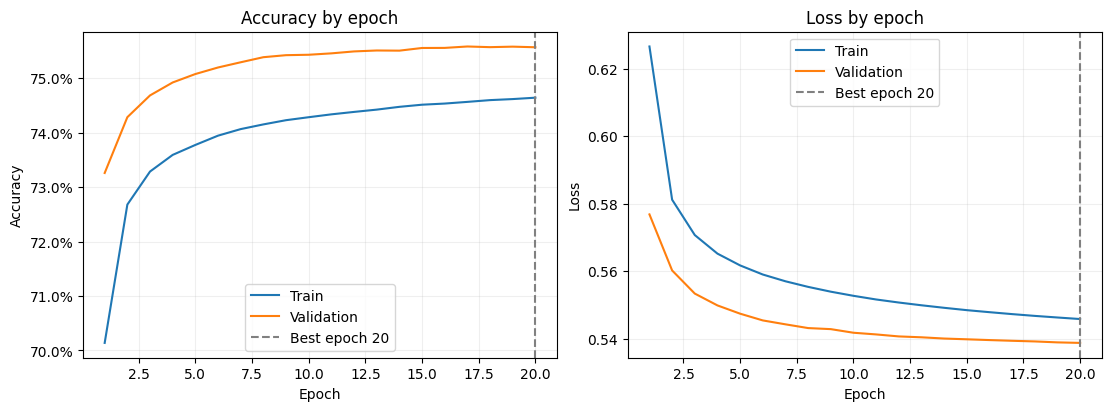

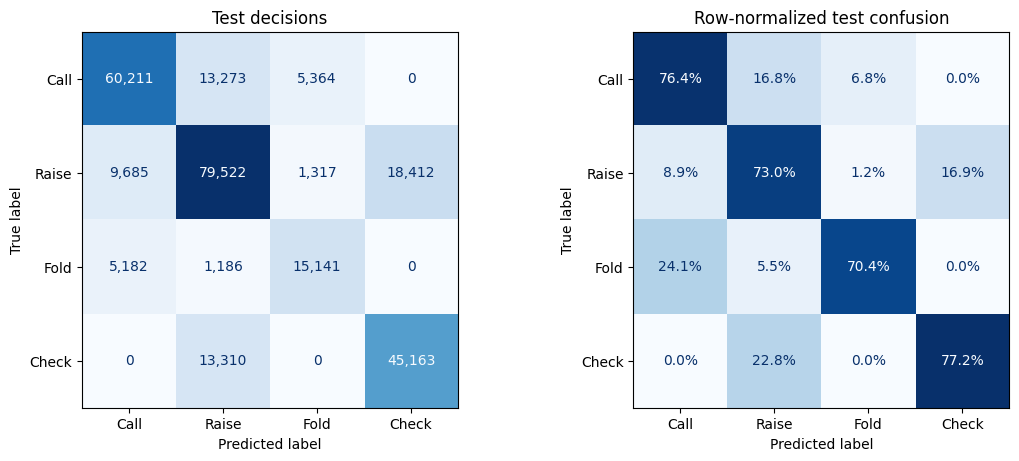

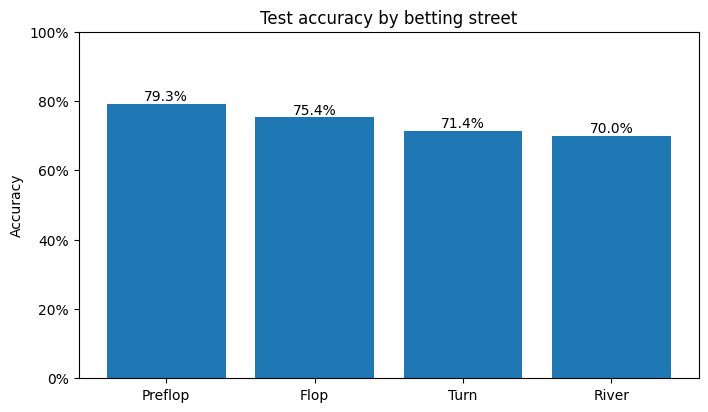

Figures saved under: /content/drive/MyDrive/poker_models/rank_cnn_figures


In [6]:
from matplotlib.ticker import PercentFormatter

# Learning curves
if LOG_PATH.is_file():
    curves=pd.read_csv(LOG_PATH)
    epochs=np.arange(1,len(curves)+1)
    best=int(curves['val_loss'].argmin())+1
    fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
    for ax,key in zip(axes,['accuracy','loss']):
        ax.plot(epochs,curves[key],label='Train')
        ax.plot(epochs,curves['val_'+key],label='Validation')
        ax.axvline(best,ls='--',color='gray',label=f'Best epoch {best}')
        ax.set(xlabel='Epoch',ylabel=key.title(),title=key.title()+' by epoch')
        ax.grid(alpha=.2);ax.legend()
    axes[0].yaxis.set_major_formatter(PercentFormatter(1))
    fig.savefig(FIGURE_DIR/'01_position_cnn_training_curves.png',dpi=250,bbox_inches='tight')
    plt.show();plt.close(fig)

# Test confusion matrix
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for ax,norm,title,fmt in [(axes[0],None,'Test decisions',',d'),
                          (axes[1],'true','Row-normalized test confusion','.1%')]:
    cm=confusion_matrix(y_test,test_pred,labels=[0,1,2,3],normalize=norm)
    ConfusionMatrixDisplay(cm,display_labels=ACTION_NAMES).plot(
        ax=ax,cmap='Blues',colorbar=False,values_format=fmt)
    ax.set_title(title)
fig.savefig(FIGURE_DIR/'02_position_cnn_test_confusion.png',dpi=250,bbox_inches='tight')
plt.show();plt.close(fig)

# Accuracy by street
board_count=X_test_129[:,52:104].sum(axis=1)
rows=[]
for street,n in [('Preflop',0),('Flop',3),('Turn',4),('River',5)]:
    mask=board_count==n
    if mask.any():
        rows.append({'street':street,'decisions':int(mask.sum()),
                     'accuracy':float(np.mean(test_pred[mask]==y_test[mask]))})
street_df=pd.DataFrame(rows)
street_df.to_csv(FIGURE_DIR/'03_position_cnn_test_street_metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4.5))
bars=ax.bar(street_df['street'],street_df['accuracy'])
ax.bar_label(bars,labels=[f'{v:.1%}' for v in street_df['accuracy']])
ax.set(ylim=(0,1),ylabel='Accuracy',title='Test accuracy by betting street')
ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.savefig(FIGURE_DIR/'03_position_cnn_test_streets.png',dpi=250,bbox_inches='tight')
plt.show();plt.close(fig)
print('Figures saved under:',FIGURE_DIR)

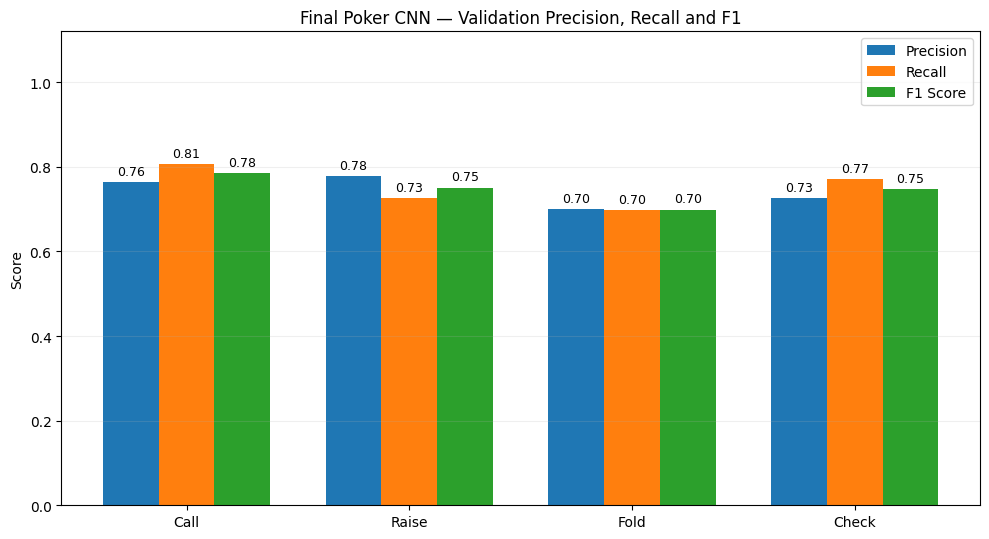

Saved: /content/drive/MyDrive/poker_models/rank_cnn_figures/validation_precision_recall_f1.png


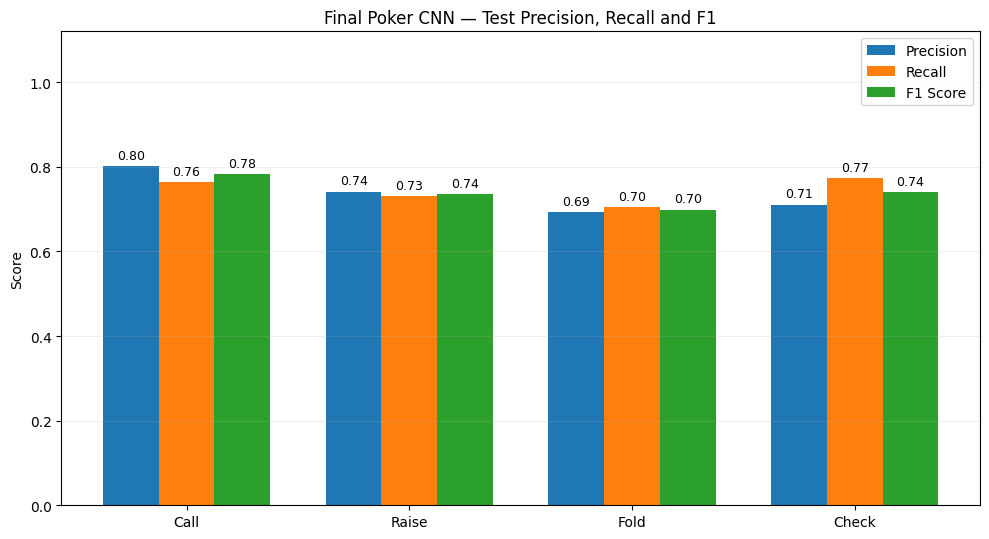

Saved: /content/drive/MyDrive/poker_models/rank_cnn_figures/test_precision_recall_f1.png


In [9]:

# ==========================================================
# PRECISION, RECALL, F1 VISUALIZATIONS
# Validation and held-out test
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np

for split_name in ("validation", "test"):

    df = evaluation_results[split_name]["classes"]

    x = np.arange(len(df))
    width = 0.25

    fig, ax = plt.subplots(figsize=(10, 5.5))

    bars_p = ax.bar(
        x - width,
        df["Precision"],
        width,
        label="Precision"
    )

    bars_r = ax.bar(
        x,
        df["Recall"],
        width,
        label="Recall"
    )

    bars_f = ax.bar(
        x + width,
        df["F1"],
        width,
        label="F1 Score"
    )

    for bars in (bars_p, bars_r, bars_f):
        ax.bar_label(
            bars,
            fmt="%.2f",
            padding=3,
            fontsize=9
        )

    ax.set_xticks(x)
    ax.set_xticklabels(df["Action"])
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("Score")
    ax.set_title(
        f"Final Poker CNN — {split_name.title()} "
        "Precision, Recall and F1"
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()

    output = (
        FIGURE_DIR /
        f"{split_name}_precision_recall_f1.png"
    )

    fig.savefig(output, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", output)


In [7]:
# OPTIONAL RECOVERY CELL — for a fresh runtime with cached arrays.
# Run after the setup and split-selection cells; do not run while training.
for split in ('train','val','test'):
    cache = MODEL_DIR / f'acpc_cnn129_{split}.npz'
    if not cache.is_file():
        raise FileNotFoundError(f'Cached features missing: {cache}. Run section 2 once.')
    with np.load(cache) as saved:
        if 'manifest_hash' not in saved or str(saved['manifest_hash'].item()) != MANIFEST_HASH:
            raise ValueError(f'Split mismatch for {cache}. Do not mix cached arrays and new splits.')
        globals()[f'X_{split}_129'] = saved['X']
        globals()[f'y_{split}'] = saved['y']
cnn = keras.models.load_model(MODEL_PATH, compile=False)
print('Recovered 129-input feature arrays and trained checkpoint.')

Recovered 129-input feature arrays and trained checkpoint.


In [10]:
# Table 3.4 — Held-out test performance

test = evaluation_results["test"]

print("TABLE 3.4 — HELD-OUT TEST PERFORMANCE")
print("----------------------------------------")
print(f"Legal-masked action accuracy: {test['masked_accuracy']:.2%}")
print(f"Macro precision:             {test['macro_precision']:.4f}")
print(f"Macro recall:                {test['macro_recall']:.4f}")
print(f"Macro F1:                    {test['macro_f1']:.4f}")
print(f"Test decisions:              {test['decisions']:,}")

TABLE 3.4 — HELD-OUT TEST PERFORMANCE
----------------------------------------
Legal-masked action accuracy: 74.71%
Macro precision:             0.7368
Macro recall:                0.7425
Macro F1:                    0.7392
Test decisions:              267,766


In [11]:

# ============================================================
# FINAL 129-INPUT CNN — RLCARD GAMEPLAY BENCHMARK
# ============================================================

import numpy as np
import pandas as pd
import rlcard
from rlcard import models
from tensorflow import keras
from pathlib import Path

# ------------------------------------------------------------
# 1. Load trained CNN
# ------------------------------------------------------------

MODEL_PATH = Path(
    "/content/drive/MyDrive/poker_models/"
    "poker_model_acpc_rank_cnn_position.keras"
)

RESULT_DIR = Path(
    "/content/drive/MyDrive/poker_models/rank_cnn_figures"
)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Saved CNN not found: {MODEL_PATH}"
    )

benchmark_cnn = keras.models.load_model(
    MODEL_PATH, compile=False
)

assert benchmark_cnn.input_shape[-1] == 129

print("Loaded final CNN:", MODEL_PATH.name)


# ------------------------------------------------------------
# 2. Build exactly 129 input features from a live game
# ------------------------------------------------------------

def build_live_features(env, state, player, first_actors):

    raw = state["raw_obs"]
    hole_cards = raw["hand"]
    board_cards = raw["public_cards"]

    # RLCard's own card ordering (must match training).
    card_index = env.card2index

    hole = np.zeros(52, dtype=np.float32)
    board = np.zeros(52, dtype=np.float32)

    for card in hole_cards:
        hole[card_index[card]] = 1.0

    for card in board_cards:
        board[card_index[card]] = 1.0

    observation = np.asarray(
        state["obs"], dtype=np.float32
    ).ravel()

    # The original 20 RLCard betting features
    betting = observation[52:72]

    # Position: was this player first to act
    # on the current street?
    street = len(board_cards)

    if street not in first_actors:
        first_actors[street] = player

    position = np.array([
        float(player == first_actors[street])
    ], dtype=np.float32)

    # Legal-action mask: Call, Raise, Fold, Check
    legal = np.zeros(4, dtype=np.float32)
    legal_ids = list(state["legal_actions"])
    legal[legal_ids] = 1.0

    features = np.concatenate([
        hole,       # 52
        board,      # 52
        betting,    # 20
        position,   # 1
        legal       # 4
    ])

    assert features.shape == (129,)

    # Check that splitting the cards has not altered
    # RLCard's original combined card representation.
    assert np.array_equal(
        np.maximum(hole, board),
        observation[:52]
    )

    return features[None, :], legal


# ------------------------------------------------------------
# 3. CNN action selection with legal masking
# ------------------------------------------------------------

def cnn_action(env, state, player, first_actors):

    features, legal = build_live_features(
        env, state, player, first_actors
    )

    scores = benchmark_cnn(
        features, training=False
    ).numpy()[0]

    masked_scores = np.where(
        legal.astype(bool),
        scores,
        -np.inf
    )

    action = int(np.argmax(masked_scores))

    assert legal[action] == 1.0

    return action


# ------------------------------------------------------------
# 4. Define opponents
# ------------------------------------------------------------

# Action index: Call=0, Raise=1, Fold=2, Check=3

OPPONENTS = {
    "RLCard Rule-Based": None,
    "Random": [1, 1, 1, 1],
    "Passive": [5, 1, 2, 5],
    "Aggressive": [2, 6, 1, 2],
}

rule_agents = models.load(
    "limit-holdem-rule-v1"
).agents


# ------------------------------------------------------------
# 5. Run a benchmark against one opponent
# ------------------------------------------------------------

def benchmark_opponent(
    opponent_name,
    weights,
    n_hands=2000,
    seed=2026
):

    env = rlcard.make(
        "limit-holdem",
        config={"seed": seed}
    )

    rng = np.random.default_rng(seed)

    payoffs = np.empty(
        n_hands, dtype=np.float32
    )

    actions_taken = np.zeros(4, dtype=np.int64)

    for hand in range(n_hands):

        # Alternate seats to reduce positional bias
        bot_seat = hand % 2

        state, player = env.reset()

        # Track who acted first on each street.
        first_actors = {}

        while not env.is_over():

            # Update position tracking regardless of
            # which player acts.
            street = len(
                state["raw_obs"]["public_cards"]
            )
            if street not in first_actors:
                first_actors[street] = player

            if player == bot_seat:

                action = cnn_action(
                    env, state, player, first_actors
                )
                actions_taken[action] += 1

                state, player = env.step(action)

            elif opponent_name == "RLCard Rule-Based":

                # Built-in rule agent uses raw actions.
                action = rule_agents[player].step(state)

                if action not in state["raw_legal_actions"]:
                    raise RuntimeError(
                        f"Rule agent selected illegal action: {action}"
                    )

                state, player = env.step(
                    action, raw_action=True
                )

            else:

                legal_ids = list(state["legal_actions"])

                w = np.asarray(
                    weights, dtype=np.float64
                )[legal_ids]

                probabilities = w / w.sum()

                action = int(rng.choice(
                    legal_ids, p=probabilities
                ))

                state, player = env.step(action)

        payoffs[hand] = env.get_payoffs()[bot_seat]

        if (hand + 1) % 500 == 0:
            print(
                f"{opponent_name}: "
                f"{hand + 1:,}/{n_hands:,} hands",
                flush=True
            )

    return {
        "Opponent": opponent_name,
        "Hands": n_hands,
        "Mean payoff": float(np.mean(payoffs)),
        "Std error": float(
            np.std(payoffs, ddof=1) / np.sqrt(n_hands)
        ),
        "Win rate": float(np.mean(payoffs > 0)),
        "Loss rate": float(np.mean(payoffs < 0)),
        "Tie rate": float(np.mean(payoffs == 0)),
        "Calls": int(actions_taken[0]),
        "Raises": int(actions_taken[1]),
        "Folds": int(actions_taken[2]),
        "Checks": int(actions_taken[3]),
    }


# ------------------------------------------------------------
# 6. Run all four opponents
# ------------------------------------------------------------

N_HANDS = 2000
SEED = 2026

results = []

for name, weights in OPPONENTS.items():

    print(f"\nBenchmarking against {name}...")

    result = benchmark_opponent(
        opponent_name=name,
        weights=weights,
        n_hands=N_HANDS,
        seed=SEED
    )

    results.append(result)

    print(
        f"{name}: "
        f"{result['Mean payoff']:+.4f} "
        "RLCard payoff units per hand"
    )


# ------------------------------------------------------------
# 7. Results table and save to Drive
# ------------------------------------------------------------

benchmark_df = pd.DataFrame(results)

display(benchmark_df.round(4))

output_path = RESULT_DIR / "final_cnn_gameplay_benchmark.csv"

benchmark_df.to_csv(output_path, index=False)

print("\nBenchmark saved to:", output_path)


Loaded final CNN: poker_model_acpc_rank_cnn_position.keras

Benchmarking against RLCard Rule-Based...
RLCard Rule-Based: 500/2,000 hands
RLCard Rule-Based: 1,000/2,000 hands
RLCard Rule-Based: 1,500/2,000 hands
RLCard Rule-Based: 2,000/2,000 hands
RLCard Rule-Based: +0.6087 RLCard payoff units per hand

Benchmarking against Random...
Random: 500/2,000 hands
Random: 1,000/2,000 hands
Random: 1,500/2,000 hands
Random: 2,000/2,000 hands
Random: +1.4675 RLCard payoff units per hand

Benchmarking against Passive...
Passive: 500/2,000 hands
Passive: 1,000/2,000 hands
Passive: 1,500/2,000 hands
Passive: 2,000/2,000 hands
Passive: +1.1697 RLCard payoff units per hand

Benchmarking against Aggressive...
Aggressive: 500/2,000 hands
Aggressive: 1,000/2,000 hands
Aggressive: 1,500/2,000 hands
Aggressive: 2,000/2,000 hands
Aggressive: +1.5477 RLCard payoff units per hand


,Opponent,Hands,Mean payoff,Std error,Win rate,Loss rate,Tie rate,Calls,Raises,Folds,Checks
0,RLCard Rule-Based,2000,0.6087,0.0678,0.8695,0.1285,0.0020,1190,732,182,26
1,Random,2000,1.4675,0.0630,0.8445,0.1555,0.0000,1753,1292,243,770
2,Passive,2000,1.1697,0.0584,0.7920,0.2005,0.0075,980,1694,189,1973
3,Aggressive,2000,1.5477,0.1418,0.5965,0.3950,0.0085,3982,2079,543,697



Benchmark saved to: /content/drive/MyDrive/poker_models/rank_cnn_figures/final_cnn_gameplay_benchmark.csv


In [12]:

# ======================================================
# TABLE 3.5 — FINAL CNN GAMEPLAY PERFORMANCE
# ======================================================

import pandas as pd
from IPython.display import display

table_35 = benchmark_df[
    ["Opponent", "Hands", "Mean payoff", "Std error", "Win rate"]
].copy()

table_35.columns = [
    "Opponent",
    "Hands played",
    "Mean payoff / hand",
    "Standard error",
    "Win rate"
]

# Format for easy insertion into Word
table_35["Hands played"] = table_35["Hands played"].map(
    lambda x: f"{int(x):,}"
)

table_35["Mean payoff / hand"] = table_35[
    "Mean payoff / hand"
].map(lambda x: f"{x:+.4f}")

table_35["Standard error"] = table_35[
    "Standard error"
].map(lambda x: f"{x:.4f}")

table_35["Win rate"] = table_35[
    "Win rate"
].map(lambda x: f"{x:.2%}")

print("TABLE 3.5 — CNN GAMEPLAY BENCHMARK")
display(table_35)

# Save a copy for the report
output = RESULT_DIR / "table_3_5_gameplay_results.csv"
table_35.to_csv(output, index=False)

print("Saved:", output)


TABLE 3.5 — CNN GAMEPLAY BENCHMARK


,Opponent,Hands played,Mean payoff / hand,Standard error,Win rate
0,RLCard Rule-Based,"2,000",+0.6087,0.0678,86.95%
1,Random,"2,000",+1.4675,0.0630,84.45%
2,Passive,"2,000",+1.1697,0.0584,79.20%
3,Aggressive,"2,000",+1.5477,0.1418,59.65%


Saved: /content/drive/MyDrive/poker_models/rank_cnn_figures/table_3_5_gameplay_results.csv
